<a href="https://colab.research.google.com/github/Nadine-Ali26/MLIOps/blob/main/Customer_Segmentation_Task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv(r"/content/Customer Segmentation Dataset.csv")
df

,Unnamed: 0,Income (k$),Spending Score (1-100),Age
0,0,20,15,22
1,1,22,18,25
2,2,18,12,21
3,3,25,20,28
4,4,23,14,24
5,5,19,22,26
6,6,27,17,23
7,7,21,10,29
8,8,80,85,24
9,9,85,90,27


In [3]:
df.drop(columns=["Unnamed: 0"], inplace=True)
df

,Income (k$),Spending Score (1-100),Age
0,20,15,22
1,22,18,25
2,18,12,21
3,25,20,28
4,23,14,24
5,19,22,26
6,27,17,23
7,21,10,29
8,80,85,24
9,85,90,27


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)
X_scaled

array([[-0.8563918 , -0.87267537, -1.06677334],
       [-0.79260098, -0.78605747, -0.82432485],
       [-0.92018263, -0.95929327, -1.1475895 ],
       [-0.69691474, -0.7283122 , -0.58187637],
       [-0.76070557, -0.90154801, -0.90514101],
       [-0.88828721, -0.67056693, -0.74350869],
       [-0.63312392, -0.8149301 , -0.98595718],
       [-0.82449639, -1.01703854, -0.5010602 ],
       [ 1.0573329 ,  1.14840903, -0.90514101],
       [ 1.21680995,  1.2927722 , -0.66269253],
       [ 0.99354207,  1.06179113, -1.06677334],
       [ 1.37628701,  1.23502693, -0.42024404],
       [ 1.12112372,  1.43713537, -0.74350869],
       [ 1.31249619,  1.00404586, -0.58187637],
       [ 0.92975125,  1.35051747, -0.98595718],
       [ 1.44007784,  1.17728166, -0.33942788],
       [-0.92018263,  1.14840903, -0.90514101],
       [-0.79260098,  1.2927722 , -0.66269253],
       [-0.69691474,  1.06179113, -1.1475895 ],
       [-0.8563918 ,  1.43713537, -0.5010602 ],
       [-0.60122851,  1.23502693, -0.824

In [11]:

Kmeans=KMeans(n_clusters=4,random_state=42,n_init=10)
Kmeans.fit(X_scaled)
predict=Kmeans.predict(X_scaled)
df['KMeans_Cluster']=predict
df['KMeans_Cluster'].value_counts()

,count
KMeans_Cluster,
0,16
2,8
3,8
1,8


In [14]:
Kmeans.cluster_centers_
Kmeans.inertia_

21.01207266611522

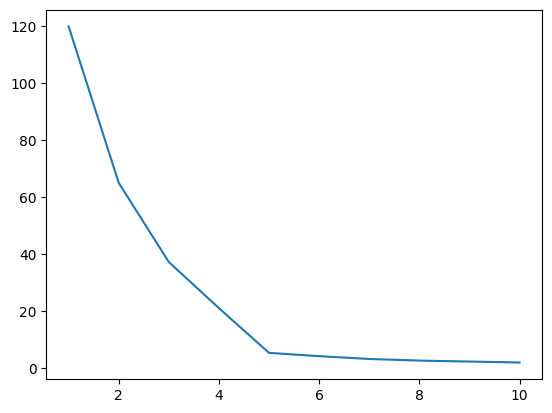

In [16]:
interia=[]
K=range(1,11)
for i in K:
  Kmeans=KMeans(n_clusters=i,random_state=42,n_init=10)
  Kmeans.fit(X_scaled)
  predict=Kmeans.predict(X_scaled)
  interia.append(Kmeans.inertia_)

plt.plot(K,interia)
plt.show()


In [27]:
eps = [0.3, 0.5, 0.7, 1.0, 0.5, 0.7, 1.0, 0.7, 1.0]
min_samples = [3, 3, 3, 3, 5, 5, 5, 8, 8]

results = []

for i in range(len(eps)):
    dbscan = DBSCAN(
        eps=eps[i],
        min_samples=min_samples[i]
    )

    y_dbscan = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(y_dbscan) - {-1})
    n_noise = (y_dbscan == -1).sum()

    results.append ({'eps': eps[i],'min_samples': min_samples[i],'number_of_clusters': n_clusters,
                   'number_of_noise': n_noise})

predict = pd.DataFrame(results)

predict


,eps,min_samples,number_of_clusters,number_of_noise
0,0.3,3,4,18
1,0.5,3,5,0
2,0.7,3,5,0
3,1.0,3,5,0
4,0.5,5,5,2
5,0.7,5,5,0
6,1.0,5,5,0
7,0.7,8,3,16
8,1.0,8,5,0


eps=0.3, min_samples=3, Clusters=4, Noise=18


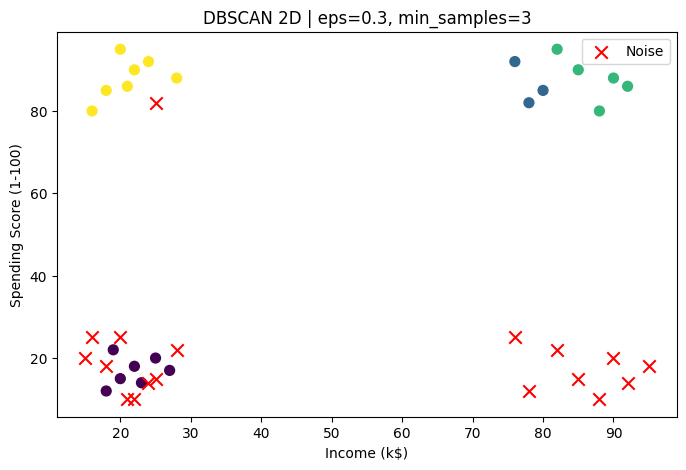

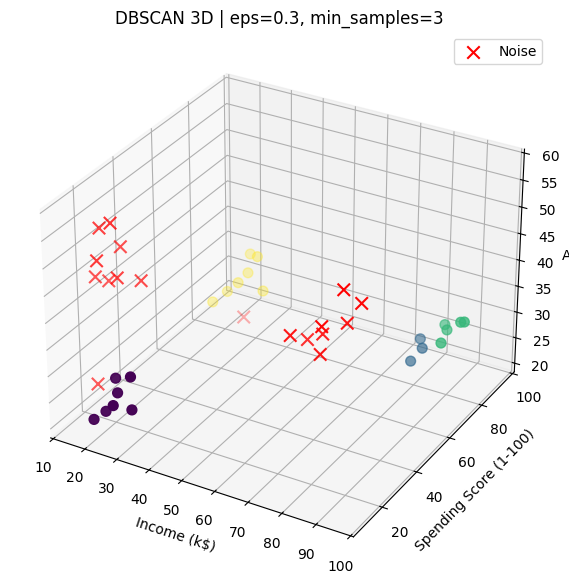

eps=0.5, min_samples=5, Clusters=5, Noise=2


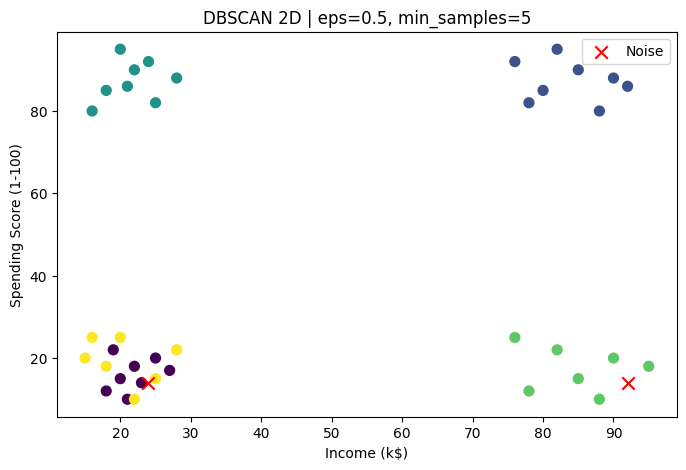

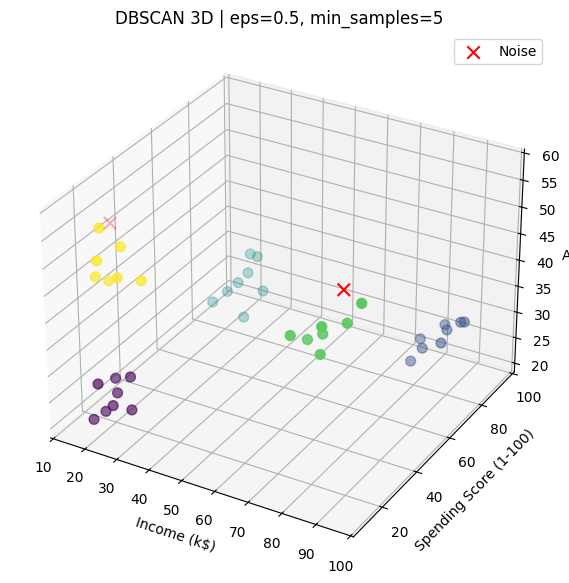

eps=1.0, min_samples=8, Clusters=5, Noise=0


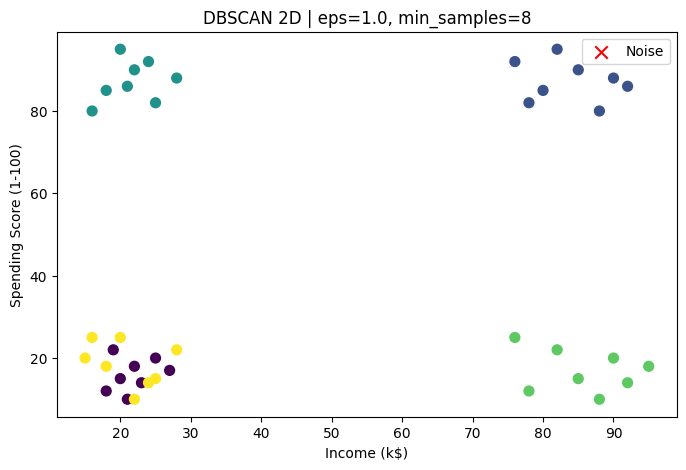

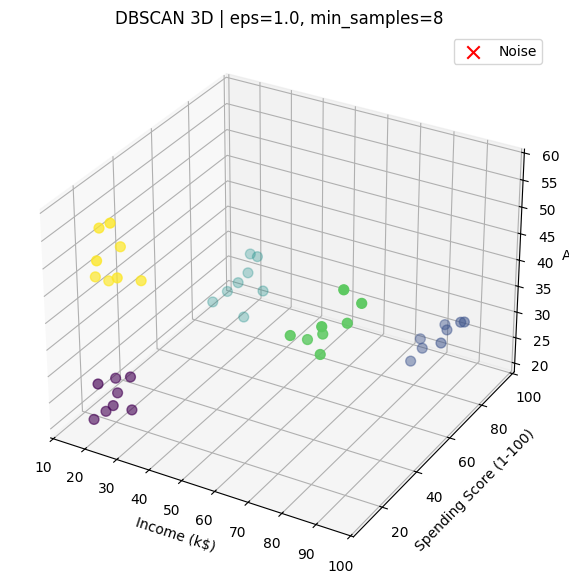

In [31]:
from sklearn.cluster import DBSCAN

parameter_combinations = [
    {'eps': 0.3, 'min_samples': 3},
    {'eps': 0.5, 'min_samples': 5},
    {'eps': 1.0, 'min_samples': 8}
]


features = ['Income (k$)', 'Spending Score (1-100)']
X_2d = X_scaled[:, :2]

income = df['Income (k$)'].to_numpy()
spending = df['Spending Score (1-100)'].to_numpy()
age = df['Age'].to_numpy()

for params in parameter_combinations:

    dbscan = DBSCAN(eps=params['eps'],min_samples=params['min_samples'])

    labels = dbscan.fit_predict(X_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(f"eps={params['eps']}, "f"min_samples={params['min_samples']}, "f"Clusters={n_clusters}, Noise={n_noise}")

    noise = labels == -1

    plt.figure(figsize=(8, 5))
    plt.scatter(income[~noise],spending[~noise],c=labels[~noise],cmap='viridis',s=50)

    plt.scatter(income[noise],spending[noise],c='red',marker='x',s=80,label='Noise')

    plt.xlabel('Income (k$)')
    plt.ylabel('Spending Score (1-100)')
    plt.title(f"DBSCAN 2D | eps={params['eps']}, "f"min_samples={params['min_samples']}")
    plt.legend()
    plt.show()

    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection='3d')

    ax.scatter(income[~noise],spending[~noise],age[~noise],c=labels[~noise],cmap='viridis',s=50)

    ax.scatter(income[noise],spending[noise],age[noise],c='red',marker='x',s=80,label='Noise')

    ax.set_xlabel('Income (k$)')
    ax.set_ylabel('Spending Score (1-100)')
    ax.set_zlabel('Age')
    ax.set_title(f"DBSCAN 3D | eps={params['eps']}, "f"min_samples={params['min_samples']}")
    ax.legend()
    plt.show()